# Green Light Analytics: SQL queries -> charts

Each section runs one of our SQL queries with `pd.read_sql`, then draws the chart for the slide. The queries run on the 8 table CSVs from `imdb_build_tables.ipynb`, loaded into a small SQLite database in memory, so the notebook needs no MySQL connection and no password. The SQL is the same as in our MySQL query file.

## Setup

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3

# No MySQL connection needed: load 8 table CSVs into a small database inside Python
# (sqlite3 comes with Python, nothing to install, no password).
# The same SQL queries we wrote for MySQL run on it unchanged.
tables_dir = "../data/clean"
table_names = ["directors", "actors", "genres", "certificates",
               "movies", "movie_genres", "movie_cast", "ratings"]

engine = sqlite3.connect(":memory:")
for name in table_names:
    pd.read_csv(f"{tables_dir}/{name}.csv").to_sql(name, engine, index=False)
    print("loaded", name)

# chart style: one blue for data, a darker blue to highlight the key bar, grey text
BLUE = "#86b6ef"        # normal bars
HIGHLIGHT = "#2a78d6"   # the bar we talk about
TEXT = "#52514e"

plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TEXT, "xtick.color": TEXT,
    "ytick.color": TEXT, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.grid": True, "grid.color": "#e5e4df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

def hbar(data, label_col, value_col, title, xlabel, fmt="{:,.0f}"):
    """Horizontal bar chart, biggest on top, top bar highlighted, value at the end of each bar."""
    data = data.sort_values(value_col)
    colors = [HIGHLIGHT if v == data[value_col].max() else BLUE for v in data[value_col]]
    fig, ax = plt.subplots()
    bars = ax.barh(data[label_col], data[value_col], color=colors, height=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in data[value_col]], padding=4, color=TEXT, fontsize=9)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    plt.tight_layout()
    plt.show()

loaded directors
loaded actors
loaded genres
loaded certificates
loaded movies
loaded movie_genres
loaded movie_cast
loaded ratings


## Q1. Genres: most top-rated films and highest box office

Top-rated = IMDb rating >= 8.5. The temporary table is replaced by a `WITH` (CTE), because `pd.read_sql` runs one statement at a time.

In [5]:
q1 = """
WITH genre_stats AS (
    SELECT g.genre_name,
           COUNT(*)                         AS films,
           SUM(r.imdb_rating >= 8.5)        AS top_rated_films,
           SUM(m.gross_revenue)             AS total_gross,
           AVG(m.gross_revenue)             AS avg_gross
    FROM genres g
    JOIN movie_genres mg ON g.genre_id = mg.genre_id
    JOIN movies m        ON mg.movie_id = m.movie_id
    JOIN ratings r       ON m.movie_id = r.movie_id
    GROUP BY g.genre_id, g.genre_name
)
SELECT * FROM genre_stats
"""
genre_stats = pd.read_sql(q1, engine)
genre_stats["total_gross_m"] = genre_stats["total_gross"] / 1_000_000
genre_stats["avg_gross_m"] = genre_stats["avg_gross"] / 1_000_000
genre_stats.sort_values("top_rated_films", ascending=False).head(10)

,genre_name,films,top_rated_films,total_gross,avg_gross,total_gross_m,avg_gross_m
6,Drama,724,42,2.749762e+10,4.605967e+07,27497.622629,46.059669
5,Crime,209,14,6.956304e+09,4.068014e+07,6956.303927,40.680140
0,Action,189,13,2.203333e+10,1.412393e+08,22033.328131,141.239283
1,Adventure,196,12,2.817432e+10,1.657313e+08,28174.317369,165.731279
4,Comedy,233,6,1.224793e+10,6.412530e+07,12247.931579,64.125296
18,Thriller,137,6,6.454429e+09,5.867663e+07,6454.428931,58.676627
16,Sci-Fi,67,6,9.029610e+09,1.480264e+08,9029.610220,148.026397
14,Mystery,99,5,3.467048e+09,4.127438e+07,3467.048100,41.274382
3,Biography,109,5,5.304578e+09,5.525602e+07,5304.577796,55.256019
15,Romance,125,5,4.318397e+09,4.035885e+07,4318.396644,40.358847


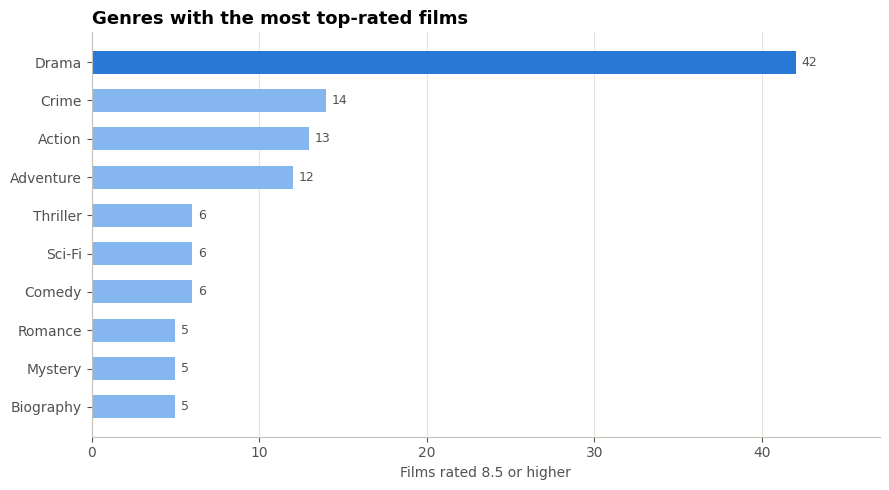

In [6]:
hbar(genre_stats.nlargest(10, "top_rated_films"), "genre_name", "top_rated_films",
     "Genres with the most top-rated films", "Films rated 8.5 or higher")

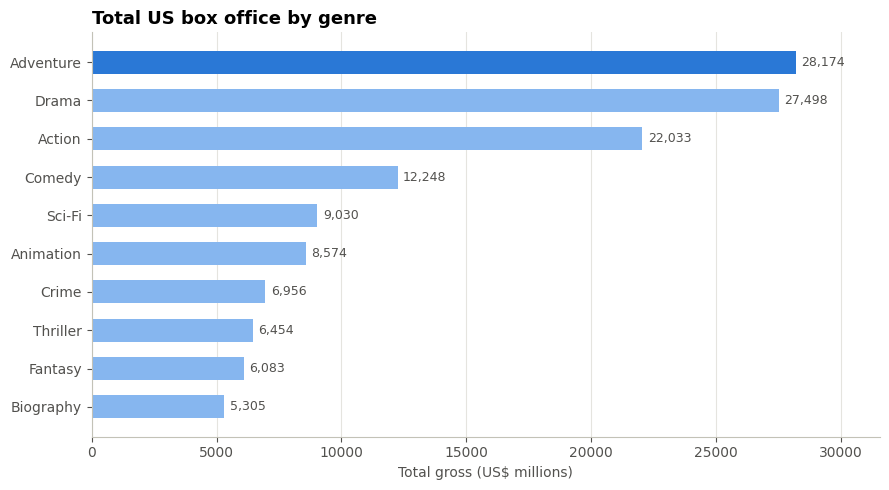

In [7]:
hbar(genre_stats.nlargest(10, "total_gross_m"), "genre_name", "total_gross_m",
     "Total US box office by genre", "Total gross (US$ millions)")

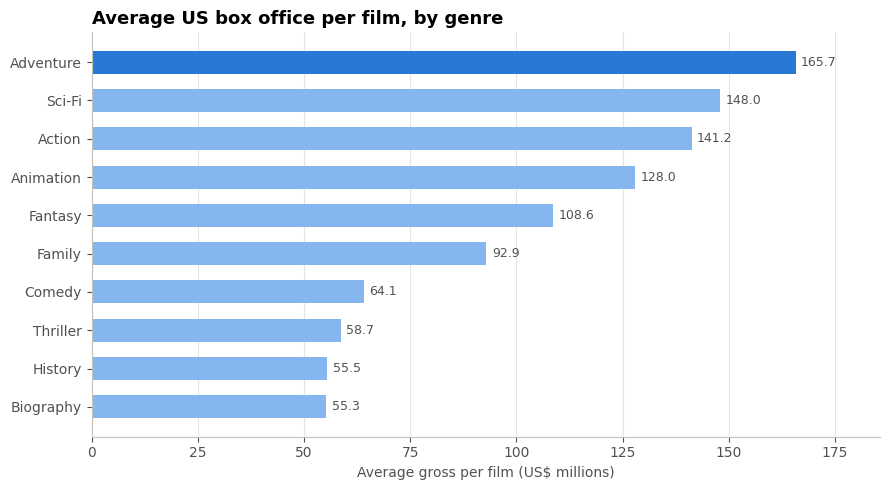

In [8]:
# Fairer comparison: average gross per film (big genres don't win just by having more films)
hbar(genre_stats[genre_stats["films"] >= 20].nlargest(10, "avg_gross_m"), "genre_name", "avg_gross_m",
     "Average US box office per film, by genre", "Average gross per film (US$ millions)", fmt="{:,.1f}")

## Q2. Do critics (meta_score) and audiences (imdb_rating) agree?

Only the 843 films with a real Meta_score are used. IMDb rating is multiplied by 10 so both scores are out of 100.

In [9]:
q2_avg = """
SELECT ROUND(AVG(imdb_rating * 10), 1) AS avg_audience_score,
       ROUND(AVG(meta_score), 1)       AS avg_critic_score
FROM ratings
WHERE meta_score IS NOT NULL
"""
pd.read_sql(q2_avg, engine)

,avg_audience_score,avg_critic_score
0,79.3,78.0


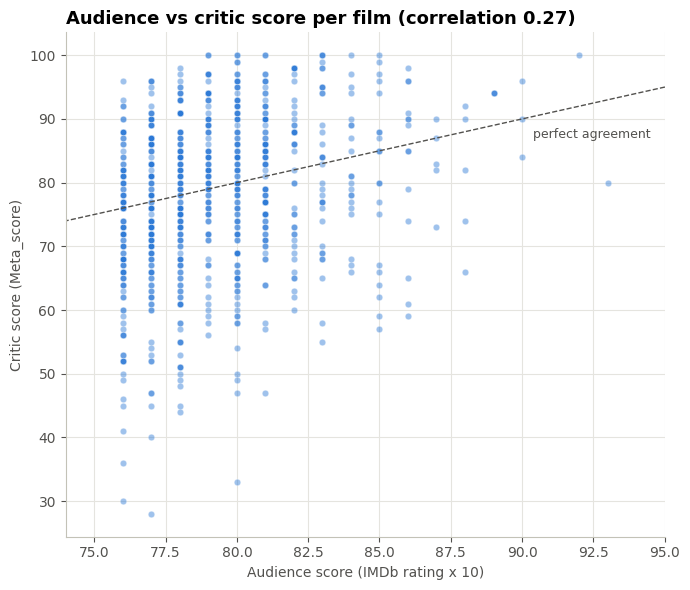

In [10]:
q2_scores = """
SELECT r.imdb_rating * 10 AS audience_score, r.meta_score AS critic_score
FROM ratings r
WHERE r.meta_score IS NOT NULL
"""
scores = pd.read_sql(q2_scores, engine)
corr = scores["audience_score"].corr(scores["critic_score"])

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(scores["audience_score"], scores["critic_score"], s=22, color=HIGHLIGHT, alpha=0.45, edgecolor="white", linewidth=0.5)
ax.plot([60, 100], [60, 100], color=TEXT, linewidth=1, linestyle="--")
ax.text(94.5, 87, "perfect agreement", color=TEXT, fontsize=9, ha="right")
ax.set_xlim(74, 95)
ax.set_title(f"Audience vs critic score per film (correlation {corr:.2f})", loc="left")
ax.set_xlabel("Audience score (IMDb rating x 10)")
ax.set_ylabel("Critic score (Meta_score)")
plt.tight_layout()
plt.show()

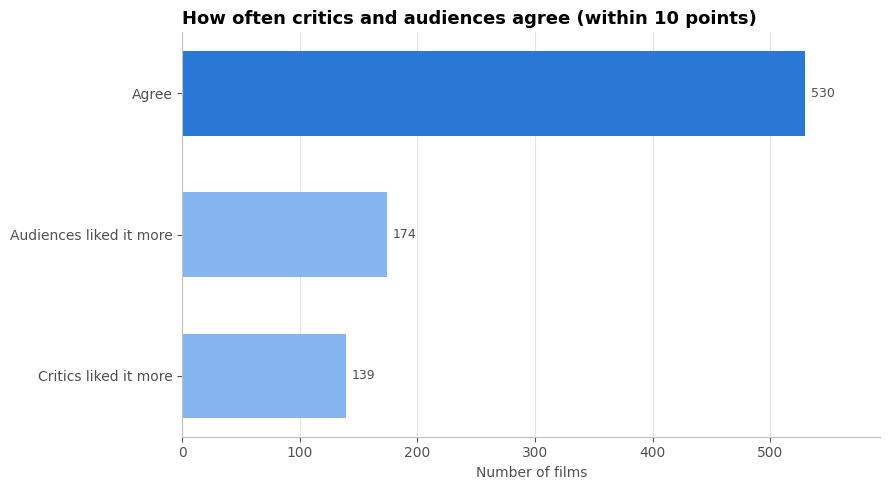

In [11]:
q2_agree = """
SELECT CASE
         WHEN ABS(meta_score - imdb_rating * 10) <= 10 THEN 'Agree'
         WHEN meta_score > imdb_rating * 10           THEN 'Critics liked it more'
         ELSE 'Audiences liked it more'
       END AS opinion,
       COUNT(*) AS films
FROM ratings
WHERE meta_score IS NOT NULL
GROUP BY opinion
"""
agree = pd.read_sql(q2_agree, engine)
hbar(agree, "opinion", "films", "How often critics and audiences agree (within 10 points)", "Number of films")

In [12]:
q2_disagree = """
SELECT m.movie_title,
       ROUND(r.imdb_rating * 10, 2) AS audience_score,
       r.meta_score                 AS critic_score,
       ABS(r.meta_score - r.imdb_rating * 10) AS gap
FROM movies m
JOIN ratings r ON m.movie_id = r.movie_id
WHERE r.meta_score IS NOT NULL
ORDER BY gap DESC
LIMIT 10
"""
pd.read_sql(q2_disagree, engine)   # show as a table on the slide

,movie_title,audience_score,critic_score,gap
0,I Am Sam,77.0,28.0,49.0
1,Tropa de Elite,80.0,33.0,47.0
2,The Butterfly Effect,76.0,30.0,46.0
3,Seven Pounds,76.0,36.0,40.0
4,Kai po che!,77.0,40.0,37.0
5,Fear and Loathing in Las Vegas,76.0,41.0,35.0
6,Pink Floyd: The Wall,81.0,47.0,34.0
7,The Boondock Saints,78.0,44.0,34.0
8,Bound by Honor,80.0,47.0,33.0
9,Predator,78.0,45.0,33.0


## Q3. Talent: directors and actors with consistently high ratings (at least 4 films)

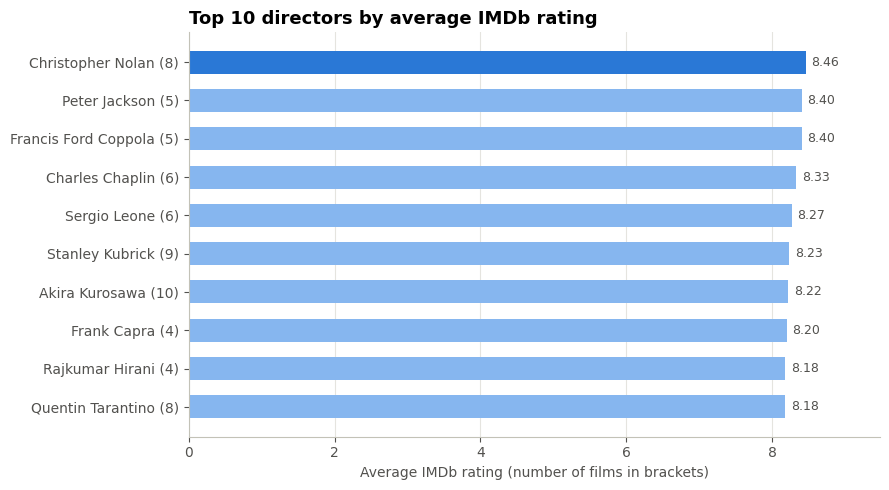

In [13]:
q3_directors = """
SELECT d.director_name,
       COUNT(*)                     AS films,
       ROUND(AVG(r.imdb_rating), 2) AS avg_rating,
       ROUND(AVG(m.gross_revenue))  AS avg_gross
FROM directors d
JOIN movies m  ON d.director_id = m.director_id
JOIN ratings r ON m.movie_id = r.movie_id
GROUP BY d.director_id, d.director_name
HAVING COUNT(*) >= 4
ORDER BY avg_rating DESC
LIMIT 10
"""
directors = pd.read_sql(q3_directors, engine)
directors["label"] = directors["director_name"] + " (" + directors["films"].astype(str) + ")"
hbar(directors, "label", "avg_rating", "Top 10 directors by average IMDb rating",
     "Average IMDb rating (number of films in brackets)", fmt="{:.2f}")

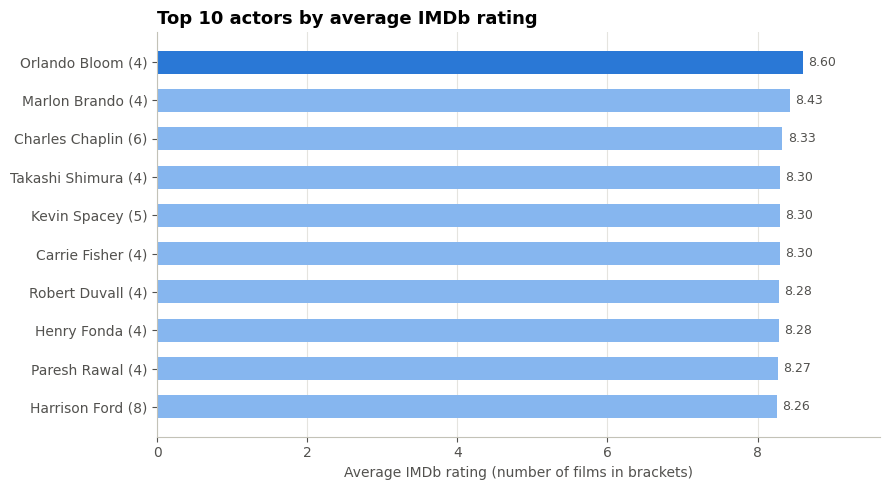

In [14]:
q3_actors = """
SELECT a.actor_name,
       COUNT(*)                     AS films,
       ROUND(AVG(r.imdb_rating), 2) AS avg_rating,
       ROUND(AVG(m.gross_revenue))  AS avg_gross
FROM actors a
JOIN movie_cast mc ON a.actor_id = mc.actor_id
JOIN movies m      ON mc.movie_id = m.movie_id
JOIN ratings r     ON m.movie_id = r.movie_id
GROUP BY a.actor_id, a.actor_name
HAVING COUNT(*) >= 4
ORDER BY avg_rating DESC
LIMIT 10
"""
actors = pd.read_sql(q3_actors, engine)
actors["label"] = actors["actor_name"] + " (" + actors["films"].astype(str) + ")"
hbar(actors, "label", "avg_rating", "Top 10 actors by average IMDb rating",
     "Average IMDb rating (number of films in brackets)", fmt="{:.2f}")

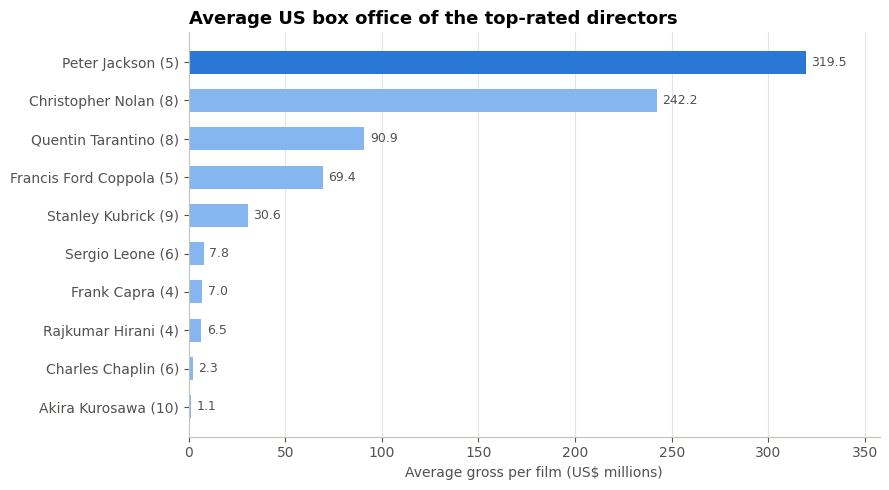

In [15]:
# "Profitable" part of the talent question: same directors, average box office
directors["avg_gross_m"] = directors["avg_gross"] / 1_000_000
hbar(directors.dropna(subset=["avg_gross_m"]), "label", "avg_gross_m",
     "Average US box office of the top-rated directors", "Average gross per film (US$ millions)", fmt="{:,.1f}")